## 선형회귀 실습

### 학습 데이터 준비

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

# 선형회귀 모델 임포트
from sklearn.linear_model import LinearRegression

# 한글 폰트 설정
# plt.rcParams["font.family"] = "Malgun Gothic"   # 윈도우 사용자
plt.rcParams["font.family"] = "AppleGothic"     # 맥 사용자

# 데이터 (딕셔너리)
data = {
    "hours": [1, 2, 3, 4, 5],
    "scores": [47, 53, 65, 73, 87]
}

# 판다스 데이터프레임으로 전환
df = pd.DataFrame(data)
df

,hours,scores
0,1,47
1,2,53
2,3,65
3,4,73
4,5,87


### 입력 데이터와 정답데이터 분리

In [2]:
# 입력 데이터 (피쳐:Feature) : 2차원 - 독립변수
X = df[["hours"]]   # 공부시간

# 출력 데이터 (Target) : 1차원 - 정답 : 종속변수
y = df["scores"]    # 시험점수

### 모델 생성 및 학습

In [3]:
# 선형회귀 모델 객체 생성
model = LinearRegression()
# 모델 학습
model.fit(X, y)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[10.]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](1,)",['hours']
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,35
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)


### 결과 확인

In [5]:
# 다중 선형회귀의 경우 결과값이 배열로 리턴
# 기울기는 배열 리턴
print(f"기울기: {model.coef_[0]:.2f}")  # 기울기 Weight
print(f"절편: {model.intercept_:.2f}")  # 절편 Bias

기울기: 10.00
절편: 35.00


### 새로운 데이터로 예측하기

In [12]:
# 6시간 학습한 학생의 성적 예측
new_data = pd.DataFrame({"hours": [6]}) # X 독립변수 1개 추가

predicted_score = model.predict(new_data)
print(f"6시간 학습한 학생의 예상 성적: {predicted_score[0]:.2f}점")

6시간 학습한 학생의 예상 성적: 95.00점


### 학습 결과 시각화

학습 데이터에 대한 예측값: [45. 55. 65. 75. 85.]


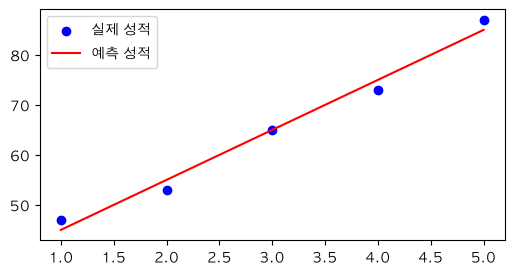

In [16]:
# 학습 데이터에 대한 예측값
y_pred = model.predict(X)
print("학습 데이터에 대한 예측값:", y_pred)

plt.figure(figsize=(6, 3))

# 실제 성적 (산점도)
plt.scatter(X["hours"], y, color="blue", label="실제 성적")

# 예측한 성적 (회귀직선)
plt.plot(X["hours"], y_pred, color="red", label="예측 성적")

plt.legend()
plt.show()
